# 单室神经元：`Cell.point` 与单 CV 电缆 `Cell`

点神经元直接写成 `Cell.point(N, length=..., radius=...)`。它是 `Cell(Morphology.from_soma(...), cv_policy=Lumped())` 的简写：声明方式（`paint`、`place`、`record`、`run`）与形态 `Cell` 相同，运行时则没有 CV 轴，`V` 的 shape 是 `(N,)`，默认 solver 是 `ralston2`。braincell 0.3 移除了早先的点神经元类；用它写的模型怎样逐行改写，见 cells 概念文档中的迁移对照表。

lumped `Cell` 与形态 `Cell` 用法相同：View 读写、训练参数、point synapse、记录，以及作为 `Network` population（既是 spike 源，也是突触目标）。它的结果与同样声明的单 CV 电缆 `Cell`（CELL-24 的对照对象）一致，只是去掉了那条长度为 1 的 CV 轴。只含一个 CV 的电缆 `Cell(pop_size=(N,))` 仍然可用：它保留 proximal、midpoint、distal 三个 electrical point，`V` 的 shape 是 `(N, 1)`。

| 对比项 | `Cell.point`（lumped） | 单 CV 电缆 `Cell` |
|---|---|---|
| 电压 shape | `(N,)` | `(N, 1)` |
| electrical point | 1 个（CV midpoint） | 3 个（proximal、midpoint、distal） |
| 电流输入 | clamp（省略 locset 即唯一位点）、`update(I_ext)`（电流或密度）、brainpy 投射 | clamp 或 input binding |
| 默认 solver | `ralston2` | `staggered` |
| 通道配置、point synapse、`Network`、View、训练参数、`record()` | 相同 | 相同 |
| 空间扩展 | 换成形态即可 | 可继续增加 branch 和 CV |


In [1]:
import time

import brainstate
import brainunit as u
import jax
import matplotlib.pyplot as plt
import numpy as np

import braincell
from braincell.filter import AllRegion, RootLocation, at

plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP"]
plt.rcParams["axes.unicode_minus"] = False

DT = 0.025 * u.ms
SOMA_LENGTH = 20.0 * u.um
SOMA_RADIUS = 10.0 * u.um
SOMA_AREA = 2.0 * u.math.pi * SOMA_RADIUS * SOMA_LENGTH
CURRENT_DENSITY = 10.0 * u.uA / u.cm**2
TOTAL_CURRENT = (CURRENT_DENSITY * SOMA_AREA).in_unit(u.nA)

print(f"backend={jax.default_backend()}, x64={jax.config.jax_enable_x64}")
print(f"膜面积={SOMA_AREA.in_unit(u.um**2)}, 等效总电流={TOTAL_CURRENT}")

backend=cpu, x64=False
膜面积=1256.6371 um^2, 等效总电流=0.12566371 nA


In [2]:
def make_soma():
    soma = braincell.Branch.from_lengths(
        lengths=[20.0] * u.um,
        radii=[10.0, 10.0] * u.um,
        type="soma",
    )
    return braincell.Morphology.from_root(soma, name="soma")


def channel_mechanisms(active):
    mechanisms = [
        braincell.mech.CableProperty(
            resting_potential=-54.3 * u.mV,
            membrane_capacitance=1.0 * u.uF / u.cm**2,
            axial_resistivity=100.0 * u.ohm * u.cm,
        ),
        braincell.mech.Channel("IL", name="leak", g_max=0.3 * u.mS / u.cm**2, E=-54.3 * u.mV),
    ]
    if active:
        mechanisms += [
            braincell.mech.Ion("SodiumFixed", E=50.0 * u.mV),
            braincell.mech.Ion("PotassiumFixed", E=-77.0 * u.mV),
            braincell.mech.Channel("Na_HH1952", name="na", g_max=120.0 * u.mS / u.cm**2),
            braincell.mech.Channel("K_HH1952", name="k", g_max=36.0 * u.mS / u.cm**2),
        ]
    return mechanisms


def build_point_cell(size, *, active, solver="rk4", clamp=None, synapse=False):
    """A lumped (point) Cell: V has shape (size,)."""
    cell = braincell.Cell.point(
        size,
        length=SOMA_LENGTH,
        radius=SOMA_RADIUS,
        V_init=-65.0 * u.mV,
        V_th=0.0 * u.mV,
        solver=solver,
    )
    cell.paint(AllRegion(), *channel_mechanisms(active))
    if clamp is not None:
        cell.place(clamp)  # the only site: the CV midpoint
    if synapse:
        cell.place(braincell.mech.Synapse("ExpSyn", name="ampa", tau=2.0 * u.ms, e=0.0 * u.mV))
    cell.record("v", braincell.observe.state("v"))
    return cell


def build_one_cv_cell(size, *, active, solver="rk4", clamp=None, synapse=False):
    cell = braincell.Cell(
        make_soma(),
        pop_size=(size,),
        cv_policy=braincell.CVPerBranch(),
        V_init=-65.0 * u.mV,
        V_th=0.0 * u.mV,
        solver=solver,
    )
    cell.paint(AllRegion(), *channel_mechanisms(active))
    if clamp is not None:
        cell.place(RootLocation(0.5), clamp)
    if synapse:
        cell.place(
            at("soma", 0.5),
            braincell.mech.Synapse("ExpSyn", name="ampa", tau=2.0 * u.ms, e=0.0 * u.mV),
        )
    cell.record("v", braincell.observe.state("v"))
    return cell

## 数值等价

下面两种 `Cell` 使用相同的圆柱面积、膜电容、反转电位、最大电导、初值和 RK4，clamp 注入由电流密度和膜面积换算得到的总电流；初始化后 HH 门控即为稳态。`Cell.point` 解点神经元方程，单 CV 电缆 `Cell` 经三点电缆方程求解：被动模型的电压一致，HH 模型只差 float32 舍入量级。


电压 shape: (4,) (Cell.point) (4, 1) (单 CV 电缆 Cell)


Passive: 单 CV 电缆 Cell 与 Cell.point 的最大差值 0 mV
HH: 单 CV 电缆 Cell 与 Cell.point 的最大差值 3.8147e-06 mV
Spike time (ms): [1.9] (Cell.point) -> [1.9] (单 CV 电缆 Cell)


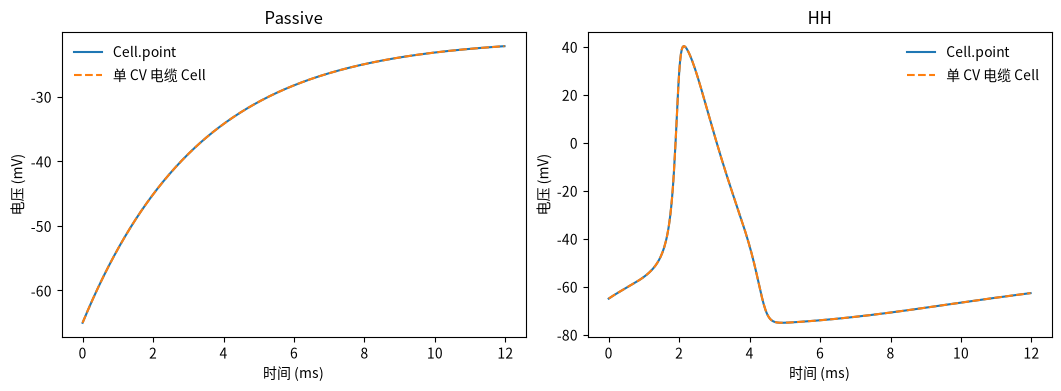

In [3]:
def run_cell(cell, duration):
    result = cell.run(dt=DT, duration=duration)
    return (
        np.asarray(result.samples["v"].time.to_decimal(u.ms)),
        np.asarray(result.samples["v"].values.to_decimal(u.mV)),
    )


def upward_crossings(times, voltage, threshold=0.0):
    voltage = np.asarray(voltage).reshape(-1)
    rows = np.flatnonzero((voltage[:-1] < threshold) & (voltage[1:] >= threshold)) + 1
    return np.asarray(times)[rows]


shape_point = build_point_cell(4, active=False)
shape_point.init_state()
shape_cell = build_one_cv_cell(4, active=False)
shape_cell.init_state()
print("电压 shape:", shape_point.V.value.shape, "(Cell.point)", shape_cell.V.value.shape, "(单 CV 电缆 Cell)")

DURATION = 12.0 * u.ms
comparisons = {}
for label, active in (("Passive", False), ("HH", True)):
    clamp = braincell.mech.CurrentClamp(durations=DURATION, amplitudes=TOTAL_CURRENT)
    point_t, point_v = run_cell(build_point_cell(1, active=active, clamp=clamp), DURATION)
    cell_t, cell_v = run_cell(build_one_cv_cell(1, active=active, clamp=clamp), DURATION)
    comparisons[label] = point_t, point_v[:, 0], cell_t, cell_v[:, 0]

for label, (point_t, point_v, cell_t, cell_v) in comparisons.items():
    print(f"{label}: 单 CV 电缆 Cell 与 Cell.point 的最大差值 {np.max(np.abs(cell_v - point_v)):.6g} mV")
point_t, point_v, cell_t, cell_v = comparisons["HH"]
print("Spike time (ms):", upward_crossings(point_t, point_v), "(Cell.point) ->",
      upward_crossings(cell_t, cell_v), "(单 CV 电缆 Cell)")

figure, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)
for axis, (label, values) in zip(axes, comparisons.items()):
    point_t, point_v, cell_t, cell_v = values
    axis.plot(point_t, point_v, label="Cell.point")
    axis.plot(cell_t, cell_v, "--", label="单 CV 电缆 Cell")
    axis.set(title=label, xlabel="时间 (ms)", ylabel="电压 (mV)")
    axis.legend(frameon=False)
plt.show()


## 由 lumped Cell 组成的网络

lumped `Cell` 可以直接加入 `Network`：`event_outputs["spike"]` 作为 spike 源，`synapses["ampa"]` 作为突触目标。

下面的 pre 和 post 都是三成员的 lumped HH population。三种 clamp 幅度产生不同的放电时间，再通过一对一 `ExpSyn` connection 驱动 post。同一网络再用单 CV 电缆 `Cell`（同为 `rk4`）搭一遍作对照：两者的 spike 事件相同，电压只差浮点舍入。

Network(name='lumped', populations=2, connections=1, rows=3)
  populations:
    pre: size=3, kind=cell, model=Cell, initialized=True
    post: size=3, kind=cell, model=Cell, initialized=True
  connections:
    post: connections=1, rows=3
      drive: CellSpikeSource(Cell.spike) -> ExpSyn(ampa), rows=3
记录 shape: (800, 3) (800, 3)
事件数量: 3 3
pre: spike 事件与单 CV 电缆 Cell 相同 = True；电压最大差值 0.000124 mV
post: spike 事件与单 CV 电缆 Cell 相同 = True；电压最大差值 7.63e-06 mV


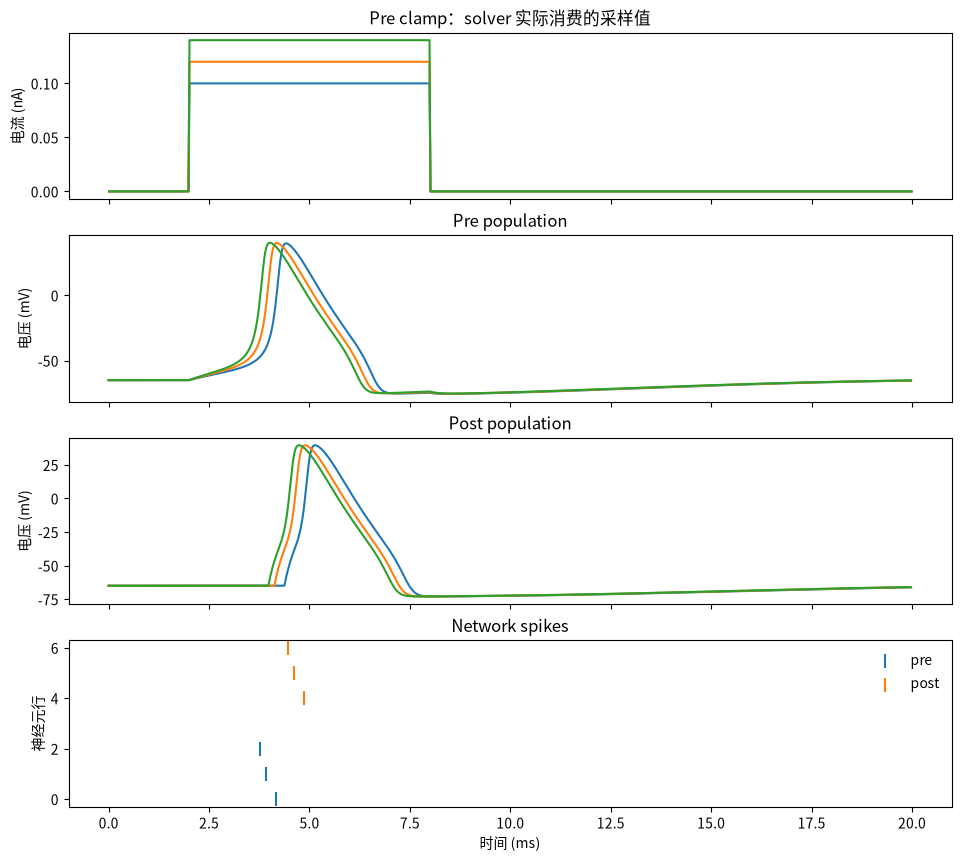

In [4]:
def drive_network(build, name):
    pre_clamp = braincell.mech.CurrentClamp(
        delay=2.0 * u.ms,
        durations=6.0 * u.ms,
        amplitudes=np.asarray([0.10, 0.12, 0.14]) * u.nA,
    )
    pre_cell = build(3, active=True, clamp=pre_clamp)
    post_cell = build(3, active=True, synapse=True)
    pre_cell.clamps.record("input")
    network = braincell.Network(name)
    pre = network.add_population("pre", pre_cell)
    post = network.add_population("post", post_cell)
    network.connect(
        "drive",
        source=pre.event_outputs["spike"],
        synapse=post.synapses["ampa"],
        weight=0.03 * u.uS,
        delay=0.2 * u.ms,
    )
    return network, pre, network.run(dt=DT, duration=20.0 * u.ms)


network, pre, network_result = drive_network(build_point_cell, "lumped")
_, _, twin_result = drive_network(build_one_cv_cell, "one_cv_twin")

pre_v = network_result.samples["pre"]["v"]
post_v = network_result.samples["post"]["v"]
input_block = network_result.samples["pre"]["input"]
pre_events = network_result.events["pre"]["spike"]
post_events = network_result.events["post"]["spike"]

print(network)
print("记录 shape:", pre_v.values.shape, post_v.values.shape)
print("事件数量:", len(pre_events.time), len(post_events.time))
for population in ("pre", "post"):
    lumped_events = network_result.events[population]["spike"]
    twin_events = twin_result.events[population]["spike"]
    same = np.array_equal(lumped_events.source_id, twin_events.source_id) and np.allclose(
        lumped_events.time.to_decimal(u.ms), twin_events.time.to_decimal(u.ms)
    )
    difference = np.max(np.abs(
        network_result.samples[population]["v"].values.to_decimal(u.mV)
        - twin_result.samples[population]["v"].values.to_decimal(u.mV)
    ))
    print(f"{population}: spike 事件与单 CV 电缆 Cell 相同 = {same}；电压最大差值 {difference:.3g} mV")

figure, axes = plt.subplots(4, 1, figsize=(9.5, 8.5), sharex=True, constrained_layout=True)
axes[0].plot(input_block.time.to_decimal(u.ms), input_block.values.to_decimal(u.nA))
axes[0].set(ylabel="电流 (nA)", title="Pre clamp：solver 实际消费的采样值")
axes[1].plot(pre_v.time.to_decimal(u.ms), pre_v.values.to_decimal(u.mV))
axes[1].set(ylabel="电压 (mV)", title="Pre population")
axes[2].plot(post_v.time.to_decimal(u.ms), post_v.values.to_decimal(u.mV))
axes[2].set(ylabel="电压 (mV)", title="Post population")
axes[3].scatter(pre_events.time.to_decimal(u.ms), pre_events.source_id, marker="|", s=100, label="pre")
axes[3].scatter(
    post_events.time.to_decimal(u.ms),
    post_events.source_id + pre.size + 1,
    marker="|",
    s=100,
    label="post",
)
axes[3].set(xlabel="时间 (ms)", ylabel="神经元行", title="Network spikes")
axes[3].legend(frameon=False)
plt.show()

## Point 放置与 solver 语义

一个单 CV branch 仍包含 proximal boundary、CV midpoint 和 distal boundary 三个 electrical point。staggered/DHS 会保留完整 point 电压：endpoint clamp 直接进入边界方程，endpoint synapse 的 `g(E-V_point)` 也在该 point 上线性化，因此电导项进入对角线、反转电位项进入 RHS。突触电流记录读取的也是 solver 实际使用的 point 电压。

显式 RK solver 目前只演化 CV midpoint 电压，尚未定义 endpoint point state 和 RK stage 内的再次采样；该扩展仍是 TODO。下面的 clamp 对比直接展示当前差异。


    solver      位置   CV role    point    CV
 staggered    prox      prox        0     0
 staggered     mid       mid        1     0
 staggered    dist      dist        2     0
       rk4    prox      prox        0     0
       rk4     mid       mid        1     0
       rk4    dist      dist        2     0


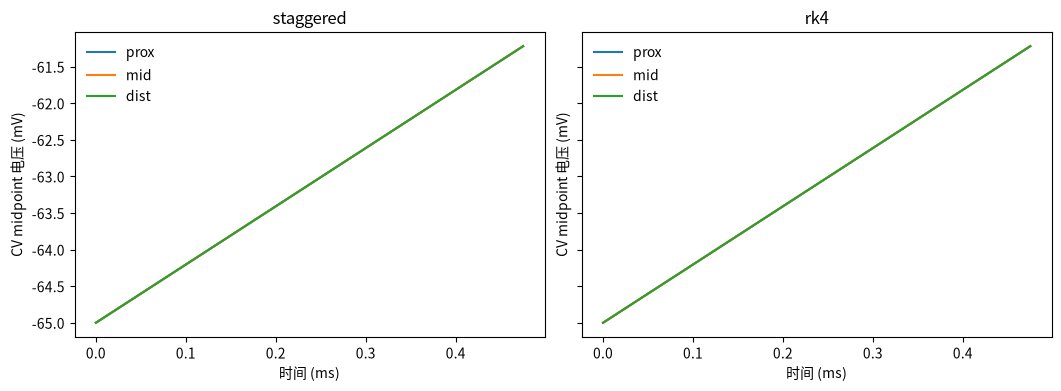

In [5]:
POSITIONS = {"prox": 0.0, "mid": 0.5, "dist": 1.0}


def location_clamp_cell(branch_x, solver):
    cell = braincell.Cell(
        make_soma(),
        pop_size=(1,),
        cv_policy=braincell.CVPerBranch(),
        V_init=-65.0 * u.mV,
        solver=solver,
    )
    cell.place(
        RootLocation(branch_x),
        braincell.mech.CurrentClamp(durations=0.5 * u.ms, amplitudes=0.1 * u.nA),
    )
    cell.record("v", braincell.observe.state("v"))
    return cell


placement_rows = []
placement_traces = {}
for solver in ("staggered", "rk4"):
    for position, branch_x in POSITIONS.items():
        cell = location_clamp_cell(branch_x, solver)
        placement = cell.point_placements[0]
        result = cell.run(dt=DT, duration=0.5 * u.ms)
        placement_rows.append((solver, position, placement.cv_position, placement.point_id, placement.cv_id))
        placement_traces[solver, position] = (
            result.samples["v"].time.to_decimal(u.ms),
            result.samples["v"].values.to_decimal(u.mV)[:, 0],
        )

print(f"{'solver':>10}  {'位置':>6}  {'CV role':>8}  {'point':>7}  {'CV':>4}")
for solver, position, role, point_id, cv_id in placement_rows:
    print(f"{solver:>10}  {position:>6}  {role:>8}  {point_id:7d}  {cv_id:4d}")

figure, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True, constrained_layout=True)
for axis, solver in zip(axes, ("staggered", "rk4")):
    for position in POSITIONS:
        time_ms, voltage_mv = placement_traces[solver, position]
        axis.plot(time_ms, voltage_mv, label=position)
    axis.set(title=solver, xlabel="时间 (ms)", ylabel="CV midpoint 电压 (mV)")
    axis.legend(frameon=False)
plt.show()

## 性能审计

`Cell.point` 用它的默认 `ralston2`，单 CV 电缆 `Cell` 沿用 `rk4`。每次运行 50 ms（2000 步）：`Cell.run` 每次调用另有约 1–2 ms 的固定开销（记录的后处理等），短运行时它会掩盖每步耗时。这里比较构建、初始化、warm-up、reset 和纯运行时间，并分别统计 differential、auxiliary 与 runtime parameter state。每个纯运行样本都在 `reset_state()` 完成并同步之后开始；三次 warm-up 用于吸收 tracing/compilation，表中 steady 值是五次同步调用的中位数。结果只描述当前机器和当前 backend，不是发布基准。


计时（run 不含 reset）：
     N         model      build       init    warm-up      reset        run    us/step
     1    Cell.point       4.27      27.59     169.46      5.489      0.911      0.456
     1     单 CV Cell       5.91      27.39     425.34      6.103      0.961      0.480
     8    Cell.point       2.64     600.82     241.71     10.955      1.105      0.552
     8     单 CV Cell       2.68     528.59     490.04     14.808      4.049      2.024
    32    Cell.point       2.73     804.39     401.42     45.771      1.697      0.848
    32     单 CV Cell       3.22     719.33     751.68     40.121     11.777      5.888
   128    Cell.point       2.60     630.53     285.70     10.603      3.392      1.696
   128     单 CV Cell       2.98     617.14     552.39     15.893     26.733     13.367
   512    Cell.point       4.87     747.94     286.59     13.934     12.218      6.109
   512     单 CV Cell       3.49     697.58     649.05     13.075     45.523     22.762
  1000    Cell.point     

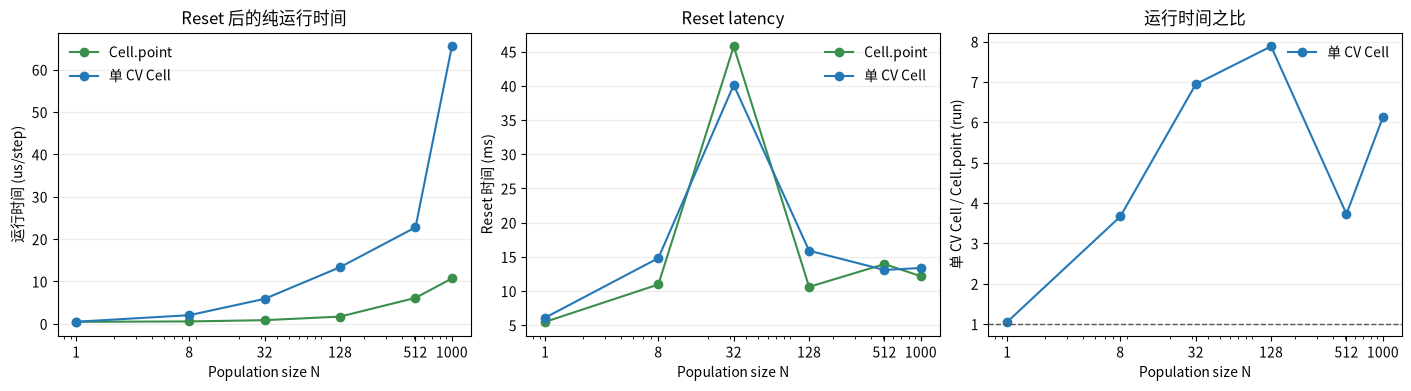

In [6]:
def state_elements(model):
    counts = {"differential": 0, "auxiliary": 0, "runtime_parameter": 0}
    for state in brainstate.graph.states(model).values():
        name = type(state).__name__
        category = (
            "differential"
            if name.startswith("DiffEq")
            else "runtime_parameter"
            if name == "RuntimeParameterState"
            else "auxiliary"
        )
        counts[category] += int(np.size(u.get_mantissa(state.value)))
    counts["total"] = sum(counts.values())
    return counts


def synchronize(model):
    jax.block_until_ready(tuple(state.value for state in brainstate.graph.states(model).values()))


def elapsed(call):
    started = time.perf_counter()
    output = call()
    jax.block_until_ready(output)
    return time.perf_counter() - started


def benchmark(size, duration=50.0 * u.ms, warmups=3, repeats=5):
    n_steps = int(round(float(duration / DT)))
    started = time.perf_counter()
    cell = build_one_cv_cell(
        size,
        active=True,
        clamp=braincell.mech.CurrentClamp(durations=duration, amplitudes=TOTAL_CURRENT),
    )
    cell_build = time.perf_counter() - started
    started = time.perf_counter()
    cell.init_state()
    cell_init = time.perf_counter() - started

    started = time.perf_counter()
    point = build_point_cell(
        size,
        active=True,
        solver="ralston2",
        clamp=braincell.mech.CurrentClamp(durations=duration, amplitudes=TOTAL_CURRENT),
    )
    point_build = time.perf_counter() - started
    started = time.perf_counter()
    point.init_state()
    point_init = time.perf_counter() - started

    rows = []
    for label, model, runner, build_s, init_s in (
        # RunResult is not a JAX pytree: wait on the recorded values, not on the result.
        ("Cell.point", point, lambda: point.run(dt=DT, duration=duration).samples["v"].values, point_build, point_init),
        ("单 CV Cell", cell, lambda: cell.run(dt=DT, duration=duration).samples["v"].values, cell_build, cell_init),
    ):

        def reset():
            model.reset_state()
            synchronize(model)

        def run_after_reset():
            reset()
            return elapsed(runner)

        warmup_s = [run_after_reset() for _ in range(warmups)]
        reset_s = [elapsed(reset) for _ in range(repeats)]
        run_s = [run_after_reset() for _ in range(repeats)]
        run_median = float(np.median(run_s))
        rows.append(
            {
                "size": size,
                "model": label,
                "build_ms": 1e3 * build_s,
                "init_ms": 1e3 * init_s,
                "warmup_ms": 1e3 * sum(warmup_s),
                "reset_ms": 1e3 * float(np.median(reset_s)),
                "run_ms": 1e3 * run_median,
                "us_per_step": 1e6 * run_median / n_steps,
                **state_elements(model),
            }
        )
    return rows


SIZES = (1, 8, 32, 128, 512, 1000)
benchmark_rows = [row for size in SIZES for row in benchmark(size)]

print("计时（run 不含 reset）：")
print(f"{'N':>6}  {'model':>12}  {'build':>9}  {'init':>9}  {'warm-up':>9}  {'reset':>9}  {'run':>9}  {'us/step':>9}")
for row in benchmark_rows:
    print(
        f"{row['size']:6d}  {row['model']:>12}  {row['build_ms']:9.2f}  "
        f"{row['init_ms']:9.2f}  {row['warmup_ms']:9.2f}  {row['reset_ms']:9.3f}  "
        f"{row['run_ms']:9.3f}  {row['us_per_step']:9.3f}"
    )

print("\nState 元素数量：")
print(f"{'N':>6}  {'model':>12}  {'differential':>14}  {'auxiliary':>10}  {'runtime':>10}  {'total':>8}")
for row in benchmark_rows:
    print(
        f"{row['size']:6d}  {row['model']:>12}  {row['differential']:14d}  "
        f"{row['auxiliary']:10d}  {row['runtime_parameter']:10d}  {row['total']:8d}"
    )

by_model = {
    model: [row for row in benchmark_rows if row["model"] == model]
    for model in ("Cell.point", "单 CV Cell")
}
colors = {"Cell.point": "#3a8f4b", "单 CV Cell": "#2478b5"}
figure, axes = plt.subplots(1, 3, figsize=(14.0, 3.8), constrained_layout=True)
for model, rows in by_model.items():
    axes[0].plot(SIZES, [row["us_per_step"] for row in rows], marker="o", label=model, color=colors[model])
    axes[1].plot(SIZES, [row["reset_ms"] for row in rows], marker="o", label=model, color=colors[model])
ratios = [
    cable["us_per_step"] / point["us_per_step"]
    for point, cable in zip(by_model["Cell.point"], by_model["单 CV Cell"])
]
axes[2].plot(SIZES, ratios, marker="o", label="单 CV Cell", color=colors["单 CV Cell"])
axes[2].axhline(1.0, color="#555555", linewidth=1.0, linestyle="--")
for axis in axes:
    axis.set_xscale("log")
    axis.set_xticks(SIZES)
    axis.set_xticklabels(SIZES)
    axis.set_xlabel("Population size N")
    axis.grid(axis="y", alpha=0.25)
    axis.legend(frameon=False)
axes[0].set(ylabel="运行时间 (us/step)", title="Reset 后的纯运行时间")
axes[1].set(ylabel="Reset 时间 (ms)", title="Reset latency")
axes[2].set(ylabel="单 CV Cell / Cell.point (run)", title="运行时间之比")
plt.show()

## 结论

点神经元用 `Cell.point`：`V` 的 shape 是 `(N,)`，声明方式与形态 `Cell` 相同，模型以后换成 `Cell(Morphology.from_swc(...))` 时不必改写 `paint`、`place` 与 `record`。

`Network`、point synapse、View 和训练参数在 lumped `Cell` 上都可用，结果与单 CV 电缆 `Cell` 一致。只有需要 proximal/distal endpoint 语义（上节的 point 放置）时，才需要单 CV 电缆 `Cell`（shape `(N, 1)`）。
